In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Parakh ML environment is ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Parakh ML environment is ready!
Pandas version: 3.1.0
NumPy version: 2.5.4


In [3]:
from pathlib import Path

project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

print("Current folder:", Path.cwd())
print("\nProject files and folders:")

for item in sorted(project_dir.iterdir()):
    print(item.name, "/" if item.is_dir() else "")

print("\nFiles inside data/:")
data_dir = project_dir / "data"

if data_dir.exists():
    for item in data_dir.iterdir():
        print(item.name)
else:
    print("The data folder does not exist yet.")

Current folder: C:\Users\poona\OneDrive\Desktop\parkh\notebooks

Project files and folders:
.venv /
data /
models /
notebooks /
README.md 
src /

Files inside data/:
reviews.csv


In [17]:
import pandas as pd

df = pd.read_csv("C:/Users/poona/Downloads/archive (1)/fake reviews dataset.csv")

print("Dataset shape:", df.shape)
print(df.columns.tolist())

Dataset shape: (40432, 4)
['category', 'rating', 'label', 'text_']


In [9]:
# Check dataset quality

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nRating distribution:")
print(df["rating"].value_counts().sort_index())

print("\nDataset information:")
df.info()

Missing values:
category    0
rating      0
label       0
text_       0
dtype: int64

Duplicate rows:
12

Label counts:
label
CG    20216
OR    20216
Name: count, dtype: int64

Rating distribution:
rating
1.0     2155
2.0     1967
3.0     3786
4.0     7965
5.0    24559
Name: count, dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  str    
 1   rating    40432 non-null  float64
 2   label     40432 non-null  str    
 3   text_     40432 non-null  str    
dtypes: float64(1), str(3)
memory usage: 1.2 MB


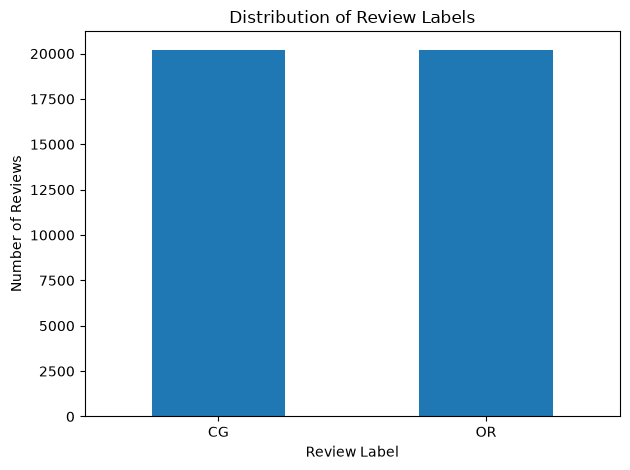

In [10]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(
    kind="bar",
    title="Distribution of Review Labels",
    xlabel="Review Label",
    ylabel="Number of Reviews",
    rot=0
)

plt.tight_layout()
plt.show()

In [11]:
# Calculate the number of words in each review
df["review_length"] = df["text_"].str.split().str.len()

print("Review length statistics:")
print(df["review_length"].describe())

print("\nAverage review length by label:")
print(df.groupby("label")["review_length"].mean().round(2))

Review length statistics:
count    40432.000000
mean        67.465423
std         69.581333
min          1.000000
25%         21.000000
50%         39.000000
75%         85.000000
max        373.000000
Name: review_length, dtype: float64

Average review length by label:
label
CG    61.29
OR    73.64
Name: review_length, dtype: float64


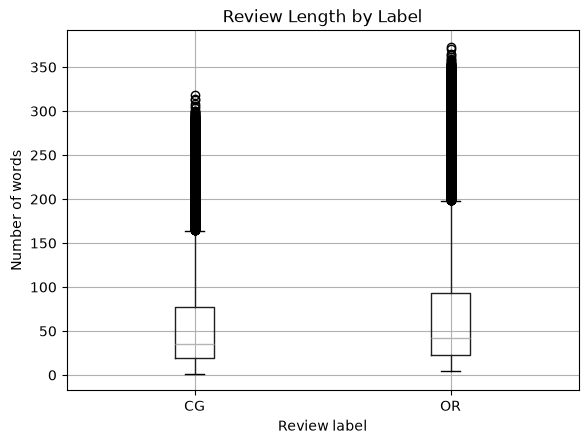

In [12]:
df.boxplot(column="review_length", by="label")
plt.title("Review Length by Label")
plt.suptitle("")
plt.xlabel("Review label")
plt.ylabel("Number of words")
plt.show()

In [13]:
# Calculate the number of words in each review
df["review_length"] = df["text_"].str.split().str.len()

print("Review length statistics:")
print(df["review_length"].describe())

print("\nAverage review length by label:")
print(df.groupby("label")["review_length"].mean().round(2))

Review length statistics:
count    40432.000000
mean        67.465423
std         69.581333
min          1.000000
25%         21.000000
50%         39.000000
75%         85.000000
max        373.000000
Name: review_length, dtype: float64

Average review length by label:
label
CG    61.29
OR    73.64
Name: review_length, dtype: float64


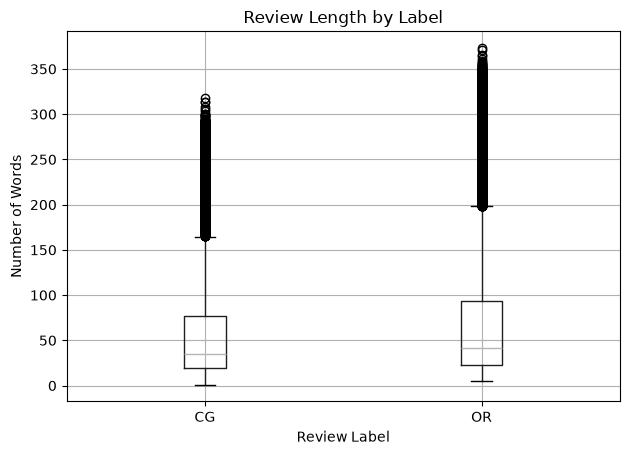

In [14]:
df.boxplot(column="review_length", by="label")

plt.title("Review Length by Label")
plt.suptitle("")
plt.xlabel("Review Label")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()

In [15]:
for label in df["label"].unique():
    print(f"\n--- {label} REVIEWS ---")

    examples = df.loc[df["label"] == label, "text_"].sample(
        n=3, random_state=42
    )

    for i, review in enumerate(examples, start=1):
        print(f"\nReview {i}: {review}")


--- CG REVIEWS ---

Review 1: I've replaced all my other fountain filters and the reservoir is still full. This is the only one I've seen that seems to work, and it is the only one I've used that does not leak. It's not clear how it will hold up if I use it on my cats, but it's pretty good.

Review 2: LT&T did not disappoint.  We have the characters we love in this book, and the way the author is able to make them fit into the story.  I think this is one of the best books I have read in a long

Review 3: Both of my dogs (full grown) love the taste. I will keep this for the next couple of months. Great price! I will definitely order again!I bought this for my puppy's tank.  It is a good size for

--- OR REVIEWS ---

Review 1: This ball and squeeker has outlasted all the other squeaky dog toys, including the hippo kong, kyjen Platypus plush squeaky eggs.  The Kyjen Invicibles Plush Snake Stuffingless dog toy is still squeaking and in pretty good shape, the pup detached some trim but cou

## Day 1 — Exploratory Data Analysis

- Total reviews: 40,432
- Missing values: 0
- Duplicate rows: 12
- CG reviews: 20,216
- OR reviews: 20,216

### Review length
- Average CG review length: [fill from output]
- Average OR review length: [fill from output]

### Initial observations
- The dataset has balanced classes.
- The dataset contains no missing values.
- Twelve duplicate rows need further inspection.
- Review length may be a useful feature, but requires evaluation.

### Limitations
- Dataset labels are not proof of real-world authenticity.
- Text patterns alone cannot reliably establish who wrote a review.

In [16]:
# Inspect the longest reviews
df["review_length"] = df["text_"].str.split().str.len()

longest_reviews = df.nlargest(5, "review_length")[
    ["category", "label", "review_length", "text_"]
]

display(longest_reviews)


,category,label,review_length,text_
15543,Movies_and_TV_5,OR,373,"There are movies for all moods, for all tastes..."
4045,Home_and_Kitchen_5,OR,371,"My interest in this 8"" pan was to satisfy my l..."
15575,Movies_and_TV_5,OR,365,ECW Extreme Evolution\nI had never seen any EC...
15531,Movies_and_TV_5,OR,364,What is going on here. First and most importa...
11985,Electronics_5,OR,361,This is the camera that DxO Labs gave the foll...


In [18]:
# Display duplicate rows for inspection
display(df[df.duplicated(keep=False)].sort_values("text_"))

,category,rating,label,text_
22305,Pet_Supplies_5,5.0,OR,Got these to give to my 8 mth old chihuahua wh...
22294,Pet_Supplies_5,5.0,OR,Got these to give to my 8 mth old chihuahua wh...
6706,Sports_and_Outdoors_5,5.0,CG,"Great, no complaints. Comfortable, phone fits ..."
6708,Sports_and_Outdoors_5,5.0,CG,"Great, no complaints. Comfortable, phone fits ..."
37296,Clothing_Shoes_and_Jewelry_5,5.0,CG,I bought this for a Halloween costume and it w...
37543,Clothing_Shoes_and_Jewelry_5,5.0,CG,I bought this for a Halloween costume and it w...
34795,Toys_and_Games_5,5.0,CG,I bought this for my son for Christmas. He lo...
34788,Toys_and_Games_5,5.0,CG,I bought this for my son for Christmas. He lo...
33208,Toys_and_Games_5,5.0,CG,I got this for my son for Christmas. He loved...
33602,Toys_and_Games_5,5.0,CG,I got this for my son for Christmas. He loved...


In [19]:
# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (40420, 4)


In [20]:
df["ends_with_punct"] = (
    df["text_"].str.strip().str[-1].isin(list(".!?"))
)

df["has_newline_char"] = df["text_"].str.contains(
    r"\\n|\n", regex=True, na=False
)

df["missing_space"] = df["text_"].str.contains(
    r"[.!?][A-Z]", regex=True, na=False
)

display(
    df.groupby("label")[
        ["ends_with_punct", "has_newline_char", "missing_space"]
    ].mean().round(3)
)

,ends_with_punct,has_newline_char,missing_space
label,,,
CG,0.350,0.169,0.288
OR,0.896,0.207,0.021


In [21]:
def to_sentiment(r):
    if r >= 4:
        return "positive"
    elif r == 3:
        return "neutral"
    else:
        return "negative"

df["sentiment"] = df["rating"].apply(to_sentiment)

print(df["sentiment"].value_counts())
print("\nClass proportions:")
print(df["sentiment"].value_counts(normalize=True).round(3))

sentiment
positive    32512
negative     4122
neutral      3786
Name: count, dtype: int64

Class proportions:
sentiment
positive    0.804
negative    0.102
neutral     0.094
Name: proportion, dtype: float64


# Day 1 — Exploratory Data Analysis (EDA)

## 1. Dataset Overview
- Dataset: Product reviews
- Total records before duplicate removal: 40,432
- Original columns: `category`, `rating`, `label`, `text_`
- Missing values: 0
- Duplicate rows identified: 12
- Records after duplicate removal: 40,420

## 2. Class Balance
- CG reviews before duplicate removal: 20,216
- OR reviews before duplicate removal: 20,216
- The original dataset has balanced authenticity labels.

## 3. Review Length Analysis
- Average CG review length: 61.29 words
- Average OR review length: 73.64 words
- OR reviews are longer on average in this dataset.
- Review length alone cannot reliably determine authenticity.

## 4. Text Quality and Dataset Limitations
- Some sampled reviews appear incomplete or concatenated.
- Review styles overlap between the CG and OR groups.
- Punctuation, newline characters and missing spaces need further investigation.
- Dataset labels do not guarantee real-world authenticity.

## 5. Sentiment Analysis
Sentiment labels are derived from star ratings:
- Ratings 4–5: Positive
- Rating 3: Neutral
- Ratings 1–2: Negative

The sentiment distribution will be recorded from the actual notebook output.

## 6. Conclusion
The dataset has no missing values and initially balanced authenticity labels. Further preprocessing and model evaluation are required before drawing conclusions about review authenticity.